In [1]:
import bezier
import numpy as np
import matplotlib.pyplot as plt

In [71]:
cp1 = np.array([0.0,0.0])
cp2 = np.array([10,10])
cp3 = np.array([20,0])
cp4 = np.array([30,10])

node_list = [cp1,cp2,cp3,cp4]

# tangents = []
# for i, point in enumerate(node_list[:-1]):
#     point_p1 = node_list[i+1]
#     tangent = point_p1 - point
#     tangent /= np.linalg.norm(tangent)
#     tangents.append(tangent)    
    
# normals = []
# for i, tangent in enumerate(tangents):
#     normal = np.array([tangent[1],-tangent[0]])
#     normals.append(normal)

Nodes = [np.array(node_list).T]
degree = len(node_list) - 1

for offset in range(1,3):
    nodes_i = []
    for i, point in enumerate(node_list):
        point_m1 = node_list[i-1] if i > 0 else point
        point_p1 = node_list[i+1] if i < len(node_list)-1 else point
        
        dp1 = point - point_m1 if i > 0 else np.array([0.0,0.0])
        dp1 = np.array([dp1[1],-dp1[0]])
        # dp1 /= np.linalg.norm(dp1) if np.linalg.norm(dp1) > 0 else 1.0
        dp2 = point_p1 - point if i < len(node_list)-1 else np.array([0.0,0.0])
        dp2 = np.array([dp2[1],-dp2[0]])
        # dp2 /= np.linalg.norm(dp2) if np.linalg.norm(dp2) > 0 else 1.0
        
        dp = dp1 + dp2
        # dp /= np.linalg.norm(dp)
        
        new_point = point + dp * offset
        nodes_i.append(new_point)

    Nodes.append(np.array(nodes_i).T)
    
Curves = []
for nodes in Nodes:
    curve = bezier.Curve(nodes, degree=nodes.shape[1]-1)
    Curves.append(curve)

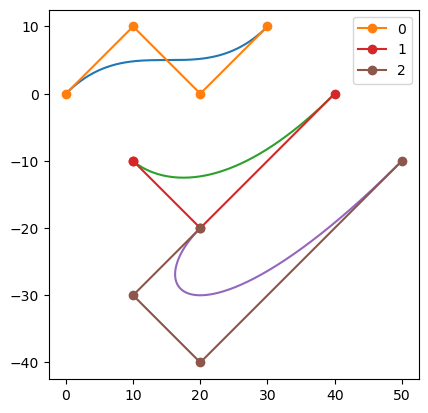

In [73]:
fig, ax = plt.subplots()

for i, (curve, nodes) in enumerate(zip(Curves, Nodes)):
    curve.plot(num_pts=256, ax=ax)
    ax.plot(*nodes, "o-", label=f"{i}")
ax.set_aspect("equal")
ax.legend()

In [60]:
import numpy as np
from scipy.special import comb
import matplotlib.pyplot as plt

def bernstein_poly(i, n, t):
    """Compute the Bernstein polynomial of n, i as a function of t."""
    return comb(n, i) * (t ** i) * ((1 - t) ** (n - i))

def bezier_curve(control_points, n_points=100):
    """Generate a Bézier curve from control points."""
    n = len(control_points) - 1
    t = np.linspace(0, 1, n_points)
    curve = np.zeros((n_points, 2))
    
    for i, point in enumerate(control_points):
        curve += np.outer(bernstein_poly(i, n, t), point)
    return curve

def offset_control_polygon(control_points, offset_distance):
    """Offset the vertices of the control polygon by a fixed distance."""
    offset_control_points = []
    n = len(control_points)

    for i in range(n):
        # Compute the tangent vector as the average direction of adjacent edges
        if i == 0:
            tangent = control_points[i + 1] - control_points[i]
        elif i == n - 1:
            tangent = control_points[i] - control_points[i - 1]
        else:
            tangent = control_points[i + 1] - control_points[i - 1]
        
        
        # Compute the normal vector
        normal = np.array([-tangent[1], tangent[0]])
        normal /= np.linalg.norm(normal)
        
        
        # if i == 0 or i == n - 1:
        #     angle = np.pi
        # else:
        #     an1 = np.arctan2(tangent[1], tangent[0])
        #     an2 = np.arctan2(control_points[i+1][1] - control_points[i-1][1], control_points[i+1][0] - control_points[i-1][0])
        #     angle = an1 - an2
        # normal *= 2 + np.cos(angle)

        # Offset the control point
        offset_point = control_points[i] + offset_distance * normal
        offset_control_points.append(offset_point)

    return np.array(offset_control_points)

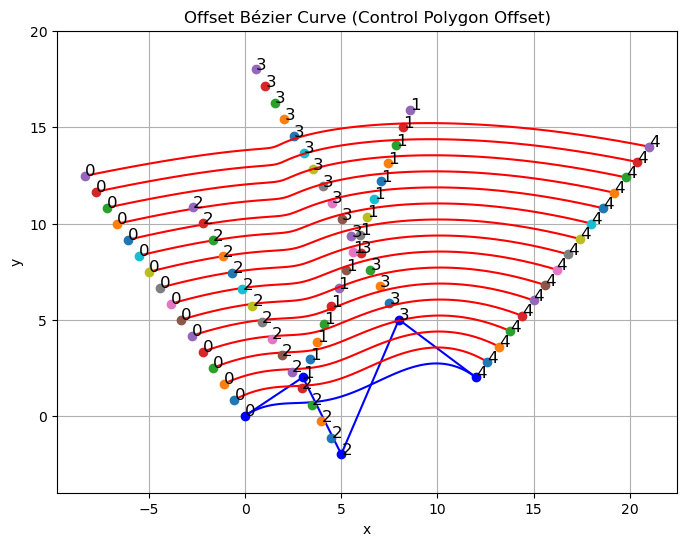

In [63]:
if __name__ == "__main__":
    control_points = np.array([
        [0, 0],
        [3, 2],
        [5, -2],
        [8, 5],
        [12, 2],
    ], dtype=float)

    n_points = 100

    # Offset the control polygon

    # Generate Bézier curves for original and offset control polygons
    bezier = bezier_curve(control_points, n_points)

    # Plot the original and offset Bézier curves
    plt.figure(figsize=(8, 6))
    plt.plot(bezier[:, 0], bezier[:, 1], label="Original Bézier Curve", color="blue")
    plt.plot(control_points[:, 0], control_points[:, 1], 'bo-', label="Original Control Points")
    # plt.plot(offset_bezier[:, 0], offset_bezier[:, 1], label="Offset Bézier Curve", color="red")
    for i, point in enumerate(control_points):
        plt.text(point[0], point[1], f"{i}", fontsize=12)
    for offset_distance in np.arange(1, 16):
        offset_control_points = offset_control_polygon(control_points, offset_distance)
        offset_bezier = bezier_curve(offset_control_points, n_points)
        plt.plot(offset_bezier[:, 0], offset_bezier[:, 1], label="Offset Bézier Curve", color="red")
        plt.plot(offset_control_points[:, 0], offset_control_points[:, 1], 'o', label="Offset Control Points")
        for i, point in enumerate(offset_control_points):
            plt.text(point[0], point[1], f"{i}", fontsize=12)
        
    # plt.legend()
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Offset Bézier Curve (Control Polygon Offset)")
    plt.grid()
    plt.axis("equal")
    plt.show()


24.999999999999996
